In [85]:
# %pip install matplotlib

In [86]:
# %pip install torch torchvision

In [87]:
# %pip install pandas

In [88]:
# %pip install kagglehub

In [89]:
import torch
import os
import kagglehub
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import shutil





In [90]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce GTX 1080 Ti


In [91]:

# Download latest version
path = kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2


In [92]:
print("Dataset path:", path)
print("\nDataset structure:")

for item in os.listdir(path):
    item_path = os.path.join(path, item)

    if os.path.isdir(item_path):
        print(f"Folder:  {item}/")
    else:
        print(f"File {item}")

print(os.listdir(path))

Dataset path: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2

Dataset structure:
Folder:  trafic_data/
['trafic_data']


In [93]:
train_images=[]
train_labels=[]

val_images=[]
val_labels=[]
for ele in os.listdir(path + "/trafic_data"):
  if(ele == 'train'):
    print(f"\nFolder : {ele}")
    location_images=os.listdir(path + "/trafic_data/" + ele + "/images")
    location_labels=os.listdir(path + "/trafic_data/" + ele + "/labels")
    print(f"Images : {len(location_images)}")
    print(f"Labels : {len(location_labels)}\n")
    train_images.append(location_images)
    train_labels.append(location_labels)
  elif(ele == 'valid'):
    print(f"\nFolder : {ele}")
    location_images=os.listdir(path + "/trafic_data/" + ele + "/images")
    location_labels=os.listdir(path + "/trafic_data/" + ele + "/labels")
    print(f"Images : {len(location_images)}")
    print(f"Labels : {len(location_labels)}\n")
    val_images.append(os.listdir(path + "/trafic_data/" + ele + "/images"))
    val_labels.append(os.listdir(path + "/trafic_data/" + ele + "/labels"))


  else:
     if os.path.isdir(path + "/trafic_data/" + ele):
        print(f"Folder:  {ele}/ \n")
     else:
        print(f"File {ele} \n")

# for ele in os.listdir(path + "/trafic_data"):
#   if os.path.isdir(path + "/trafic_data/" + ele):
#         print(f"Folder:  {ele}/ \n")
#   else:
#         print(f"File {ele} \n")

File data_1.yaml 


Folder : train
Images : 2704
Labels : 2704


Folder : valid
Images : 300
Labels : 300



In [96]:

import shutil
from pathlib import Path

src = Path(path) / "trafic_data"
dst = Path("datasets/roadvision")

# 1. Create the folder structure
for split in ["train", "val"]:
    (dst / split / "images").mkdir(parents=True, exist_ok=True)
    (dst / split / "labels").mkdir(parents=True, exist_ok=True)

# 2. Copy images and labels
for src_split, dst_split in [("train", "train"), ("valid", "val")]:
    for kind in ["images", "labels"]:
        src_dir = src / src_split / kind
        dst_dir = dst / dst_split / kind

        if not src_dir.exists():
            print(f"Folder not found: {src_dir}")
            continue

        for f in src_dir.iterdir():
            if f.is_file():
                shutil.copy2(f, dst_dir / f.name)

# 3. Check the number of files
for split in ["train", "val"]:
    for kind in ["images", "labels"]:
        folder = dst / split / kind
        files = [f for f in folder.iterdir() if f.is_file()]
        print(f"{split}/{kind}: {len(files)} files")


train/images: 2704 files
train/labels: 2704 files
val/images: 300 files
val/labels: 300 files


In [97]:

from pathlib import Path
import random
import shutil
import math

dataset_path = Path("datasets/roadvision")
random.seed(42)

train_images = dataset_path / "train" / "images"
train_labels = dataset_path / "train" / "labels"

test_images = dataset_path / "test" / "images"
test_labels = dataset_path / "test" / "labels"

# Create test folders
test_images.mkdir(parents=True, exist_ok=True)
test_labels.mkdir(parents=True, exist_ok=True)

# Find images
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = [
    p for p in train_images.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
]

# Select 20% of images
random.shuffle(images)
n_test = math.floor(len(images) * 0.20)
selected = images[:n_test]

moved = 0
missing_labels = 0

for image in selected:
    label = train_labels / f"{image.stem}.txt"

    # Move image
    shutil.move(str(image), str(test_images / image.name))

    # Move matching label if it exists
    if label.exists():
        shutil.move(str(label), str(test_labels / label.name))
    else:
        missing_labels += 1

    moved += 1

print("Images moved to test:", moved)
print("Images without matching label files:", missing_labels)
print("Images remaining in train:", len(list(train_images.iterdir())))


Images moved to test: 540
Images without matching label files: 0
Images remaining in train: 2164


In [115]:
# check if any labels is emty
data_path = Path("datasets/roadvision")

for split in ["train", "val","test"]:
    label_folder = data_path/ split / "labels"
    label_files = list(label_folder.glob("*.txt"))

    empty_files = []

    for label_file in label_files:
        text = label_file.read_text().strip()
        if text == "":
            empty_files.append(label_file.name)

    print(f"\n--- {split.upper()} ---")
    print("Total label files:", len(label_files))
    print("Empty label files:", len(empty_files))

    if empty_files:
        print("Some empty files:", empty_files[:5])
    else:
        print("Every label file has content.")


--- TRAIN ---
Total label files: 2162
Empty label files: 0
Every label file has content.

--- VAL ---
Total label files: 300
Empty label files: 0
Every label file has content.

--- TEST ---
Total label files: 539
Empty label files: 0
Every label file has content.


In [99]:

from pathlib import Path

data_path = Path("datasets/roadvision")
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val", "test"]:
    labels_folder = data_path / split / "labels"
    images_folder = data_path / split / "images"

    if not labels_folder.exists() or not images_folder.exists():
        continue

    deleted_labels = 0
    deleted_images = 0

    for label_file in labels_folder.glob("*.txt"):
        if label_file.read_text().strip() == "":
            # Delete the matching image
            for image_file in images_folder.iterdir():
                if (
                    image_file.is_file()
                    and image_file.stem == label_file.stem
                    and image_file.suffix.lower() in extensions
                ):
                    image_file.unlink()
                    deleted_images += 1

            # Delete the empty label
            label_file.unlink()
            deleted_labels += 1

    print(f"{split}: deleted {deleted_labels} empty labels")
    print(f"{split}: deleted {deleted_images} matching images")


train: deleted 1 empty labels
train: deleted 1 matching images
val: deleted 0 empty labels
val: deleted 0 matching images
test: deleted 1 empty labels
test: deleted 1 matching images


In [ ]:

yaml_src = next(Path(path).rglob("*.yaml"))   
shutil.copy(yaml_src, "data.yaml")            

print(Path("data.yaml").resolve())
print(Path("data.yaml").read_text())

/data.yaml
train: ../train/images
val: ../valid/images

nc: 21
names: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']


In [ ]:

with open("data.yaml", "r") as f:
    data = f.read()


# Add the dataset root at the top
root = Path("datasets/roadvision").resolve()
data = (
    f"path: {root}\n"
    + "test: ../test/images\n"
    + data
)

with open("data.yaml", "w") as f:
    f.write(data)

print(data)


path: /datasets/roadvision
test: ../test/images
train: ../train/images
val: ../valid/images

nc: 21
names: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus',
'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike',
'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi',
'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']



In [102]:
from pathlib import Path

dataset_path = Path("datasets/roadvision")

splits = ["train", "val","test"]
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in splits:
    images_dir = dataset_path  / split / "images"
    labels_dir = dataset_path  / split / "labels"

    if not images_dir.exists():
        print(f"{split}: dossier images introuvable")
        continue

    if not labels_dir.exists():
        print(f"{split}: dossier labels introuvable")
        continue

    images = {
        p.stem for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    }

    labels = {
        p.stem for p in labels_dir.rglob("*.txt")
    }

    missing_labels = images - labels
    missing_images = labels - images

    print(f"\n--- {split.upper()} ---")
    print("Nombre d'images :", len(images))
    print("Nombre de labels :", len(labels))
    print("Images sans annotation :", len(missing_labels))
    print("Annotations sans image :", len(missing_images))

    if missing_labels:
        print("Exemples d'images sans annotation :", list(missing_labels)[:10])

    if missing_images:
        print("Exemples d'annotations sans image :", list(missing_images)[:10])


--- TRAIN ---
Nombre d'images : 2163
Nombre de labels : 2163
Images sans annotation : 0
Annotations sans image : 0

--- VAL ---
Nombre d'images : 300
Nombre de labels : 300
Images sans annotation : 0
Annotations sans image : 0

--- TEST ---
Nombre d'images : 2019
Nombre de labels : 2019
Images sans annotation : 0
Annotations sans image : 0



--- TRAIN ---
Class 0: 58 objects
Class 1: 39 objects
Class 2: 291 objects
Class 3: 340 objects
Class 4: 2325 objects
Class 5: 3739 objects
Class 6: 2 objects
Class 7: 139 objects
Class 8: 77 objects
Class 9: 643 objects
Class 10: 1517 objects
Class 11: 886 objects
Class 12: 27 objects
Class 13: 2673 objects
Class 14: 25 objects
Class 15: 651 objects
Class 16: 34 objects
Class 17: 2285 objects
Class 18: 1098 objects
Class 19: 560 objects
Class 20: 89 objects


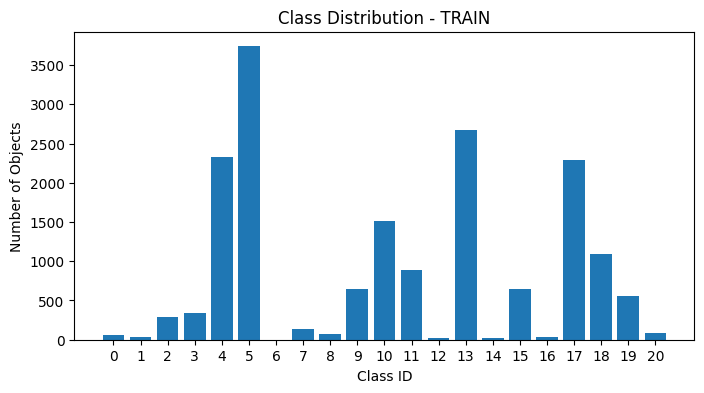


--- VAL ---
Class 3: 32 objects
Class 4: 430 objects
Class 5: 842 objects
Class 8: 2 objects
Class 9: 110 objects
Class 10: 335 objects
Class 11: 142 objects
Class 12: 1 objects
Class 13: 203 objects
Class 14: 1 objects
Class 15: 60 objects
Class 16: 19 objects
Class 17: 252 objects
Class 18: 84 objects
Class 19: 62 objects
Class 20: 9 objects


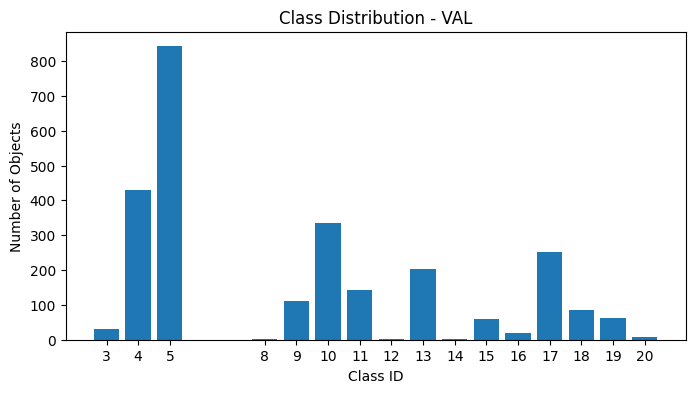


--- TEST ---
Class 0: 12 objects
Class 1: 4 objects
Class 2: 81 objects
Class 3: 87 objects
Class 4: 582 objects
Class 5: 891 objects
Class 6: 1 objects
Class 7: 30 objects
Class 8: 16 objects
Class 9: 179 objects
Class 10: 431 objects
Class 11: 195 objects
Class 12: 4 objects
Class 13: 663 objects
Class 14: 12 objects
Class 15: 147 objects
Class 16: 7 objects
Class 17: 449 objects
Class 18: 310 objects
Class 19: 133 objects
Class 20: 22 objects


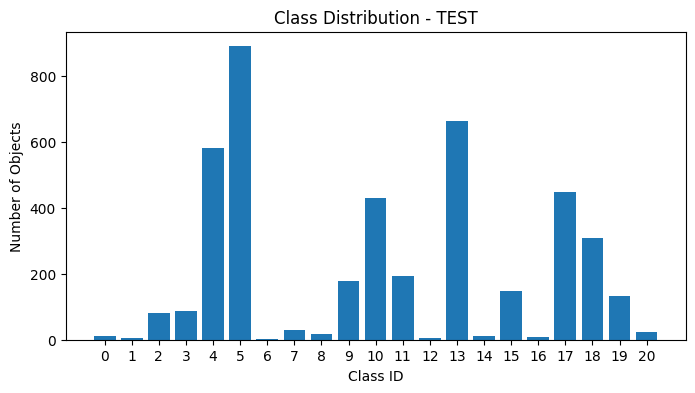

In [114]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

dataset_path = Path("datasets/roadvision")

for split in ["train", "val", "test"]:
    labels_dir = dataset_path / split / "labels"
    class_counts = Counter()

    for label_file in labels_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.split()
                if len(parts) == 5:
                    class_counts[int(parts[0])] += 1

    print(f"\n--- {split.upper()} ---")
    for class_id, count in sorted(class_counts.items()):
        print(f"Class {class_id}: {count} objects")

    # Bar plot
    plt.figure(figsize=(8, 4))
    plt.bar(class_counts.keys(), class_counts.values())
    plt.xlabel("Class ID")
    plt.ylabel("Number of Objects")
    plt.title(f"Class Distribution - {split.upper()}")
    plt.xticks(list(class_counts.keys()))
    plt.show()

In [111]:
from pathlib import Path
import hashlib

dataset_path = Path("datasets/roadvision")
splits = ["train", "val", "test"]

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


seen = {}
deleted = 0

for split in splits:

    images_dir = dataset_path / split / "images"
    labels_dir = dataset_path / split / "labels"

    if not images_dir.exists():
        continue

    for image in list(images_dir.iterdir()):

        if not image.is_file() or image.suffix.lower() not in extensions:
            continue

        h = image_hash(image)

        if h in seen:

            print("Duplicate found:")
            print("Keeping :", seen[h])
            print("Deleting:", image)

            # Delete duplicate image
            image.unlink()

            # Delete its corresponding label
            label = labels_dir / f"{image.stem}.txt"

            if label.exists():
                label.unlink()

            deleted += 1

        else:
            seen[h] = f"{split}/{image.name}"


print("\nTotal duplicate images deleted:", deleted)


Total duplicate images deleted: 0


In [112]:
for split in splits:

    images_dir = dataset_path / split / "images"

    count = sum(
        1 for f in images_dir.iterdir()
        if f.is_file() and f.suffix.lower() in extensions
    )

    print(f"{split}: {count} images")

train: 2162 images
val: 300 images
test: 539 images
